# SOLVING STELLAR STATE EQUATIONS FOR A POLYTROPIC STAR

In [1]:
from matplotlib import pyplot as plt
import numpy as np

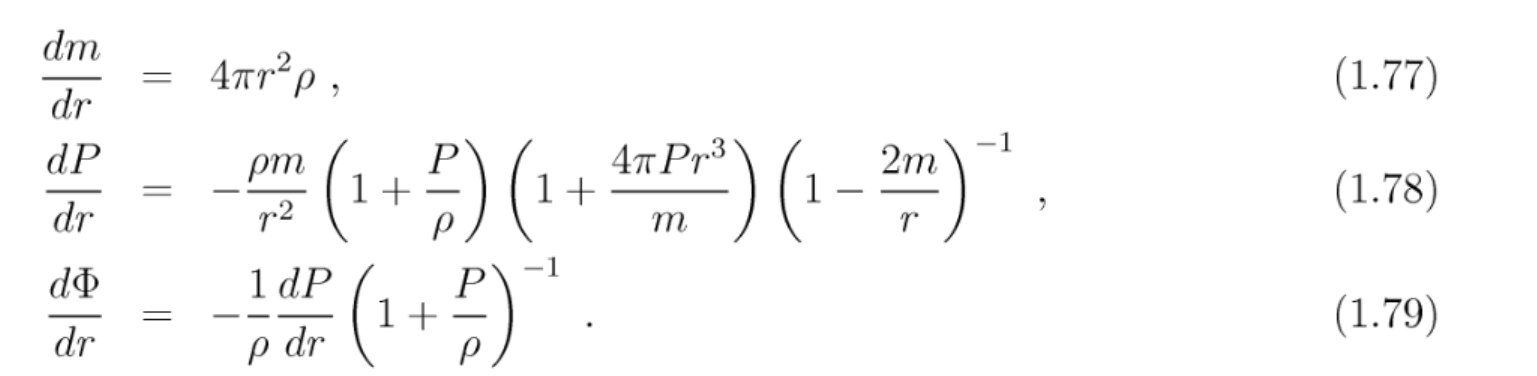

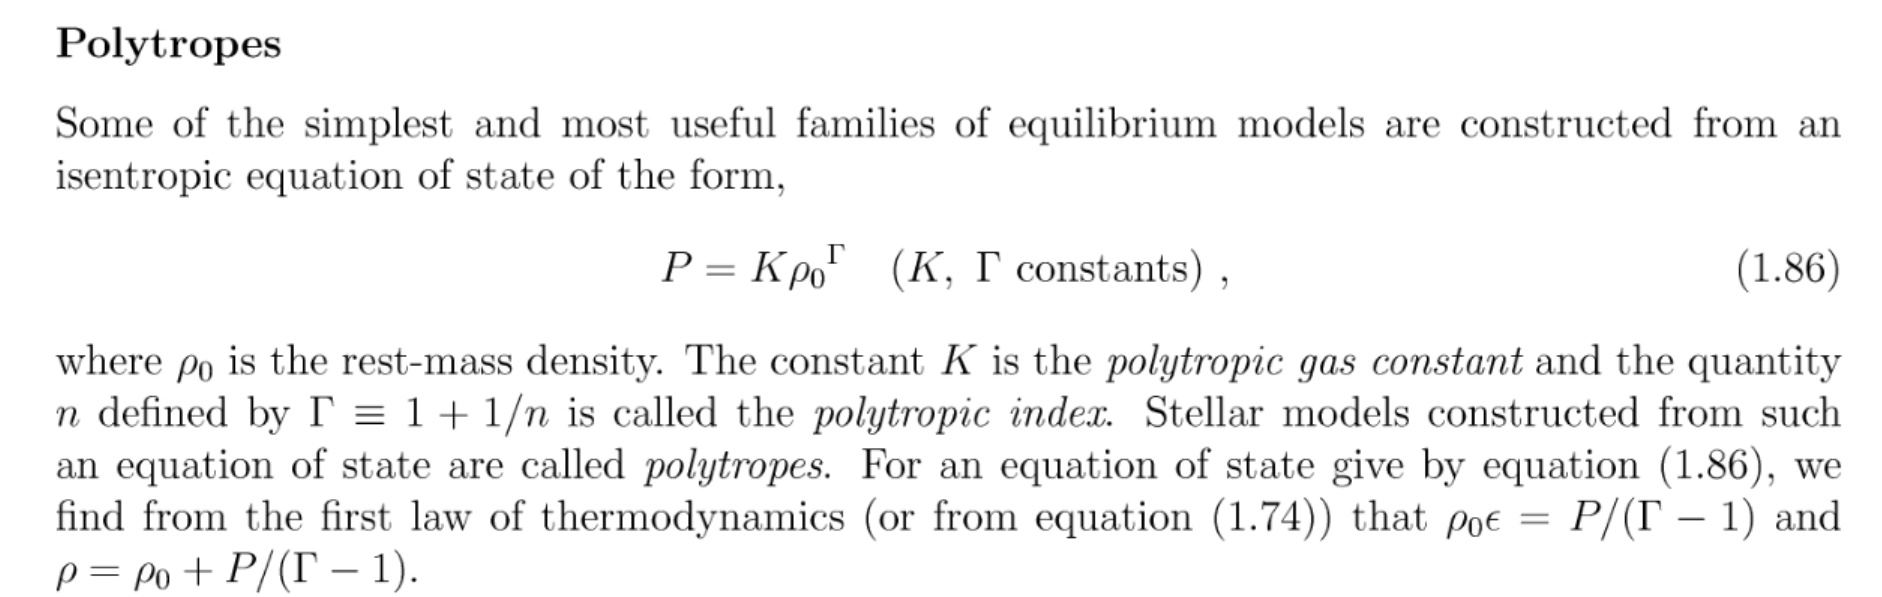

In [32]:
class polytropic_star():
    def __init__(self, n, Pc):
        self.n = n
        self.T = 1.0 + 1.0/n
        self.k = 1.0
        #arrays to hold stellar information
        self.dr = 0.001
        self.m = []
        self.P = []
        self.r = []
        #this will be the final mass and radius
        self.mass = 0.0
        self.radius = 0.0

        #the first point
        self.m.append(0.0)
        self.P.append(Pc)
        self.r.append(0.0)

    #function to calculate density given pressure
    def calc_rho(self, P):
        return (P/self.k)**(1.0/self.T) + P/(self.T-1.0)
        
    #the coupled odes to solve   
    def m_slope(self, r,rho):
        return 4.0*np.pi*r**2.0*rho
    
    def P_slope(self, r, m, P, rho):
        return -(rho*m/r**2.0)*(1.0 + P/rho)*(1.0 + 4.0*np.pi*P*r**3.0/m)*(1.0 - 2.0*m/r)**(-1.0)
    
    #the second point is placed by hand to avoid division by zero
    def calc_second_point(self):
        #hack for the second point
        self.P.append(self.P[0])
        self.r.append(self.dr)
        rho = self.calc_rho(self.P[1])
        self.m.append(self.m[0] + self.m_slope(self.r[1], rho)*self.dr) #this is Euler-Cromer to get mass at second point
    
    #do 2 rounds of RK4 to warm up the multistep method
    def RK4(self):
        for i in range(1,3):
            rho = self.calc_rho(self.P[i])
            mk1 = self.dr*self.m_slope(self.r[i],rho)
            Pk1 = self.dr*self.P_slope(self.r[i],self.m[i],self.P[i], rho)
            m_d = self.m[i] + mk1/2.0
            P_d = self.P[i] + Pk1/2.0
            r_d = self.r[i] + self.dr/2.0

            rho = self.calc_rho(P_d)
            mk2 = self.dr*self.m_slope(r_d,rho)
            Pk2 = self.dr*self.P_slope(r_d,m_d,P_d, rho)
            m_d = self.m[i] + mk2/2.0
            P_d = self.P[i] + Pk2/2.0
            r_d = self.r[i] + self.dr/2.0
            
            rho = self.calc_rho(P_d)
            mk3 = self.dr*self.m_slope(r_d,rho)
            Pk3 = self.dr*self.P_slope(r_d,m_d,P_d, rho)
            m_d = self.m[i] + mk3
            P_d = self.P[i] + Pk3
            r_d = self.r[i] + self.dr


            rho = self.calc_rho(P_d)
            mk4 = self.dr*self.m_slope(r_d,rho)
            Pk4 = self.dr*self.P_slope(r_d,m_d,P_d, rho)

            self.m.append(self.m[i] + (1.0/6.0)*(mk1 + 2.0*mk2 + 2.0*mk3 + mk4))
            self.P.append(self.P[i] + (1.0/6.0)*(Pk1 + 2.0*Pk2 + 2.0*Pk3 + Pk4))
            self.r.append(self.r[i] + self.dr)

    #then do multistep till the pressure is below zero
    def Hamming_predictor_corrector(self):
        i = 3
        while self.P[i]>0:
            
            mass_predictor = self.m[i-3] + 4*self.dr*(2*self.m_slope(self.r[i-2], self.calc_rho(self.P[i-2])) - self.m_slope(self.r[i-1], self.calc_rho(self.P[i-1])) + 2*self.m_slope(self.r[i], self.calc_rho(self.P[i])))/3
            
            pressure_predictor = self.P[i-3] + 4*self.dr*(2*self.P_slope(self.r[i-2], self.m[i-2], self.P[i-2], self.calc_rho(self.P[i-2])) - self.P_slope(self.r[i-1], self.m[i-1], self.P[i-1], self.calc_rho(self.P[i-1])) + 2*self.P_slope(self.r[i], self.m[i], self.P[i], self.calc_rho(self.P[i])))/3
            
            mass_corrector = (1/8)*(9*self.m[i] - self.m[i-2]) + 3*self.dr*(-self.m_slope(self.r[i-1], self.calc_rho(self.P[i-1])) + 2*self.m_slope(self.r[i], self.calc_rho(self.P[i])) + self.m_slope(self.r[i] + self.dr, self.calc_rho(pressure_predictor)))/8

            pressure_corrector = (1/8)*(9*self.P[i] - self.P[i-2]) + 3*self.dr*(-self.P_slope(self.r[i-1], self.m[i-1], self.P[i-1], self.calc_rho(self.P[i-1])) + 2*self.P_slope(self.r[i], self.m[i], self.P[i], self.calc_rho(self.P[i])) + self.P_slope(self.r[i] + self.dr, mass_predictor, pressure_predictor, self.calc_rho(pressure_predictor)))/8
           
            self.m.append(mass_corrector)
            self.P.append(pressure_corrector)
            self.r.append(self.r[i] + self.dr)

            i = i + 1

        #the last value when pressure falls below zero is the star's total mass and radius.
        self.mass = self.m[-1]
        self.radius = self.r[-1]
    

## Identify Maximum Mass Star/Instability Point 

In [53]:
central_pressures = np.linspace(0.001,1,201)

masses  = np.zeros(len(central_pressures))

for i in range(0, len(central_pressures)):
    star = polytropic_star(1., central_pressures[i])

    star.calc_second_point()

    star.RK4()

    star.Hamming_predictor_corrector()

    masses[i] = star.mass


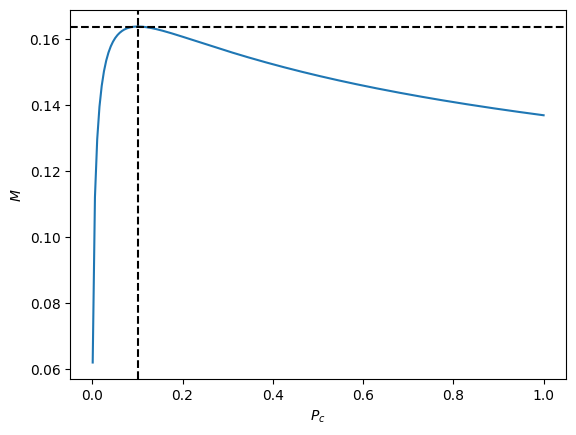

In [54]:
plt.plot(central_pressures, masses)
plt.axhline(y = masses[np.argmax(masses)], c='black', linestyle='dashed')
plt.axvline(x = central_pressures[np.argmax(masses)], c='black', linestyle='dashed')
plt.xlabel(r'$P_c$')
plt.ylabel(r'$M$')
plt.show()



The maximum mass matches Figure 1.2 of Numerical Relativity, Baumgarte and Shapiro